## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No) 
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Sử dụng 4 thuật toán: Logistic Regression, KNN, Decision Tree, RandomForest
### Độ đo: F1, Recall, ROC-AUC

### 1. Giới thiệu bài toán và dữ liệu

#### 1.1. Bài toán

- **Bối cảnh:** dữ liệu ghi lại các cuộc gọi marketing trực tiếp của một ngân hàng nhằm mời khách hàng gửi tiền kỳ hạn.
- **Mục tiêu:** dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không, giúp ngân hàng ưu tiên liên hệ nhóm khách tiềm năng và giảm chi phí cuộc gọi.
- **Input:** thông tin khách hàng và chiến dịch marketing (tuổi, nghề nghiệp, lịch sử liên hệ, chỉ số kinh tế vĩ mô...).
- **Output:** `yes` (đăng ký) hoặc `no` (không đăng ký).
- **Loại bài toán:** học có giám sát, phân loại nhị phân (Classification).

#### 1.2. Dữ liệu

Nguồn: UCI Bank Marketing, tệp `bank-additional-full.csv`, gồm 41.188 mẫu và 21 cột (20 thuộc tính và biến mục tiêu `y`).

| Nhóm thuộc tính | Các cột |
|---|---|
| Thông tin khách hàng | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` |
| Thông tin lần liên hệ hiện tại | `contact`, `month`, `day_of_week`, `duration` |
| Lịch sử chiến dịch | `campaign`, `pdays`, `previous`, `poutcome` |
| Chỉ số kinh tế vĩ mô | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |
| Biến mục tiêu | `y` |

Cột `duration` (thời lượng cuộc gọi) chỉ biết sau khi cuộc gọi kết thúc nên sẽ được loại bỏ ở mục 3 để tránh rò rỉ thông tin.

#### 1.3. Đọc dữ liệu

In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT_DIR = Path.cwd().resolve().parents[2]
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.config import RAW_DATA_PATH, PROCESSED_DATA_DIR

df = pd.read_csv(RAW_DATA_PATH, sep=';')
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 2. Khám phá dữ liệu (EDA)

#### 2.1. Tổng quan dữ liệu

Kiểm tra kích thước, kiểu dữ liệu và giá trị thiếu. Các cột đều có đủ 41.188 giá trị (không có ô trống), tuy nhiên một số cột phân loại có giá trị `unknown` (ví dụ `default`) và sẽ được xử lý ở mục 3.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
df = pd.read_csv(RAW_DATA_PATH, sep=';')

# Hiển thị 5 dòng đầu tiên
display(df.head())

# Kích thước dữ liệu
print('Số dòng:', df.shape[0])
print('Số cột:', df.shape[1])

# Thông tin dữ liệu
df.info()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Số dòng: 41188
Số cột: 21
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   

#### 2.2. Phân bố biến mục tiêu

Kiểm tra mức độ cân bằng giữa hai lớp `yes` và `no`.

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


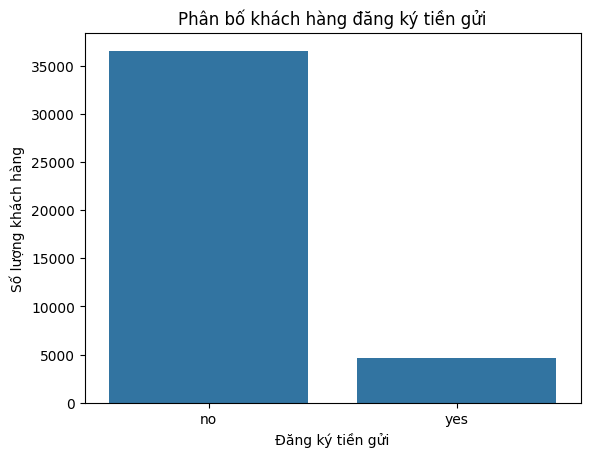

In [3]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="y")
plt.title("Phân bố khách hàng đăng ký tiền gửi")
plt.xlabel("Đăng ký tiền gửi")
plt.ylabel("Số lượng khách hàng")
plt.show()

**Nhận xét:** lớp `no` có 36.548 mẫu (88,73%) còn lớp `yes` chỉ có 4.640 mẫu (11,27%), tức dữ liệu **mất cân bằng nghiêm trọng**. Một mô hình đoán toàn bộ là `no` vẫn đạt Accuracy khoảng 88,7% nhưng không tìm được khách hàng nào đăng ký. Vì vậy đồ án dùng F1-score, Recall và ROC-AUC thay vì chỉ dựa vào Accuracy, đồng thời dùng `class_weight="balanced"` ở các mô hình.

### 3. Tiền xử lý dữ liệu

Các bước thực hiện (theo đúng thứ tự):

1. Loại bản ghi trùng và bản ghi thiếu nhãn.
2. Giữ `unknown` như một nhóm riêng của biến phân loại.
3. Loại cột `duration` để tránh rò rỉ thông tin.
4. Tách đặc trưng `X` và nhãn `y` (`no` thành 0, `yes` thành 1).
5. Chia train/test theo tỷ lệ 80/20 với `stratify=y` và `random_state=42`. Việc chia được thực hiện **trước** khi chuẩn hóa để tránh rò rỉ thông tin từ tập test.
6. Biến số: điền giá trị thiếu bằng trung vị rồi chuẩn hóa `StandardScaler`. Biến phân loại: điền giá trị thiếu bằng giá trị phổ biến nhất rồi mã hóa One-Hot.
7. Các bộ xử lý chỉ `fit` trên tập train, sau đó `transform` cho tập test.

In [4]:
from src.preprocessing import load_and_preprocess_data

X_train, X_test, y_train, y_test, X_train_raw, X_test_raw, preprocessor = load_and_preprocess_data(
    filepath=RAW_DATA_PATH,
    save_dir=PROCESSED_DATA_DIR,
)
feature_names = preprocessor.get_feature_names_out()
print('Đã tiền xử lý xong! Train:', X_train.shape, '| Test:', X_test.shape)

Đã tiền xử lý xong! Train: (32940, 62) | Test: (8236, 62)
